# Credit Scoring Model
CodeAlpha Machine Learning Internship, Task 1.
Goal: Predict whether a loan applicant is a good or risky borrower.

## Step 1: Import Libraries

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, classification_report)

## Step 2: Load Dataset
German Credit dataset (1000 applicants, 20 features) loaded from OpenML. Target: 1 = Risky (bad), 0 = Good.

In [14]:
data = fetch_openml(name="credit-g", version=1, as_frame=True)
df = data.frame.copy()

df["target"] = (df["class"] == "bad").astype(int)  
df = df.drop("class", axis=1)

print(df.shape)
print(df["target"].value_counts())
print("Missing values:", df.isnull().sum().sum())
df.head()

(1000, 21)
target
0    700
1    300
Name: count, dtype: int64
Missing values: 0


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,target
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,0
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,1
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,0
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,0
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,1


## Step 3: Exploratory Data Analysis
Checked class balance and average duration, credit amount and age for each class.

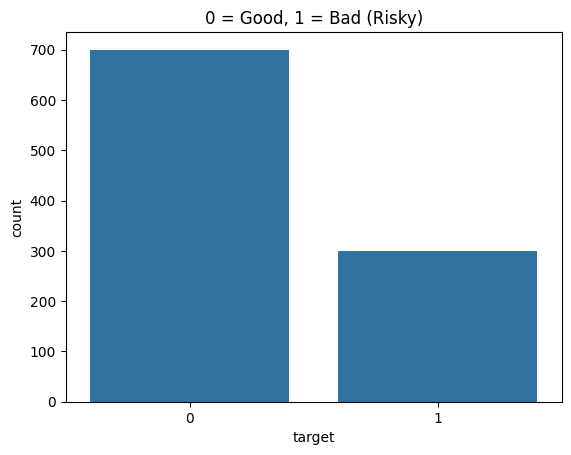

,duration,credit_amount,age
target,,,
0,19.2,2985.5,36.2
1,24.9,3938.1,34.0


In [15]:
sns.countplot(x="target", data=df)
plt.title("0 = Good, 1 = Bad (Risky)")
plt.show()

df.groupby("target")[["duration", "credit_amount", "age"]].mean().round(1)

## Step 4: Feature Engineering
Created new features: credit_per_month, log_credit_amount, is_young, long_duration, credit_age_ratio.

In [16]:
df["credit_per_month"] = df["credit_amount"] / df["duration"]      
df["log_credit_amount"] = np.log1p(df["credit_amount"])           
df["is_young"] = (df["age"] < 25).astype(int)                      
df["long_duration"] = (df["duration"] > 24).astype(int)           
df["credit_age_ratio"] = df["credit_amount"] / df["age"]

df[["credit_per_month", "log_credit_amount", "is_young", "long_duration", "credit_age_ratio"]].head()

,credit_per_month,log_credit_amount,is_young,long_duration,credit_age_ratio
0,194.833333,7.064759,0,0,17.447761
1,123.979167,8.691483,1,1,270.500000
2,174.666667,7.648263,0,0,42.775510
3,187.666667,8.972464,0,1,175.155556
4,202.916667,8.491055,0,0,91.886792


## Step 5: Train-Test Split
80% training, 20% testing (stratified).

In [17]:
X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(800, 25) (200, 25)


## Step 6: Preprocessing
Scaled numeric features (StandardScaler) and one-hot encoded categorical features.

In [18]:
cat_cols = X.select_dtypes(include=["category", "object"]).columns.tolist()
num_cols = X.select_dtypes(exclude=["category", "object"]).columns.tolist()

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

## Step 7: Model Training and Comparison
Trained Logistic Regression, Decision Tree and Random Forest with class_weight="balanced". Evaluated with Accuracy, Precision, Recall, F1 and ROC-AUC.

In [19]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
}

pipes, results, probs = {}, [], {}
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]
    pipes[name], probs[name] = pipe, prob
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
    })

results_df = pd.DataFrame(results).round(4)
results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.745,0.5506,0.8167,0.6577,0.8126
1,Decision Tree,0.615,0.4066,0.6167,0.4901,0.6655
2,Random Forest,0.760,0.6765,0.3833,0.4894,0.8050


## Step 8-9: ROC Curve and Confusion Matrix

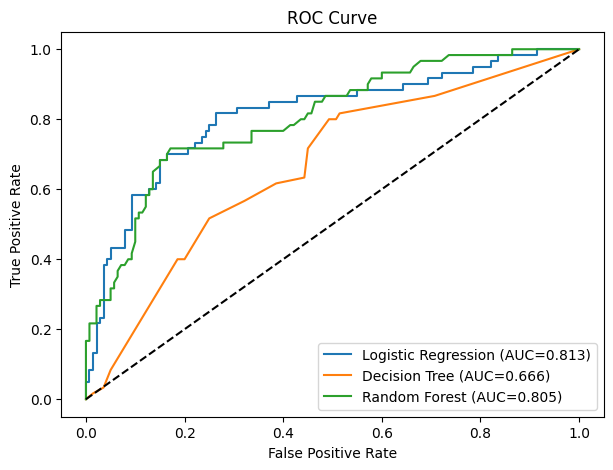

In [20]:
plt.figure(figsize=(7, 5))
for name, prob in probs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, prob):.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

Best model: Logistic Regression


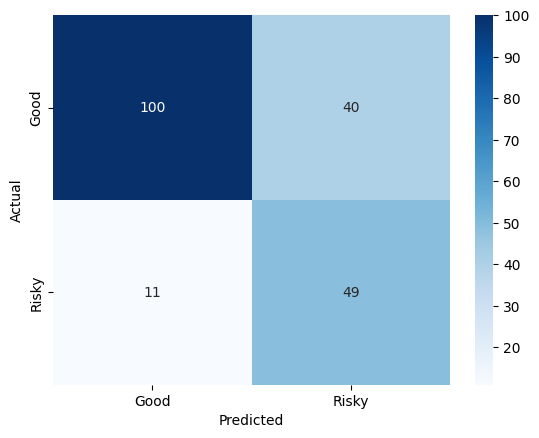

              precision    recall  f1-score   support

        Good       0.90      0.71      0.80       140
       Risky       0.55      0.82      0.66        60

    accuracy                           0.74       200
   macro avg       0.73      0.77      0.73       200
weighted avg       0.80      0.74      0.76       200



In [21]:
best = results_df.sort_values("ROC-AUC", ascending=False).iloc[0]["Model"]
print("Best model:", best)

best_pred = pipes[best].predict(X_test)
sns.heatmap(confusion_matrix(y_test, best_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Good", "Risky"], yticklabels=["Good", "Risky"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print(classification_report(y_test, best_pred, target_names=["Good", "Risky"]))

## Step 10: Feature Importance

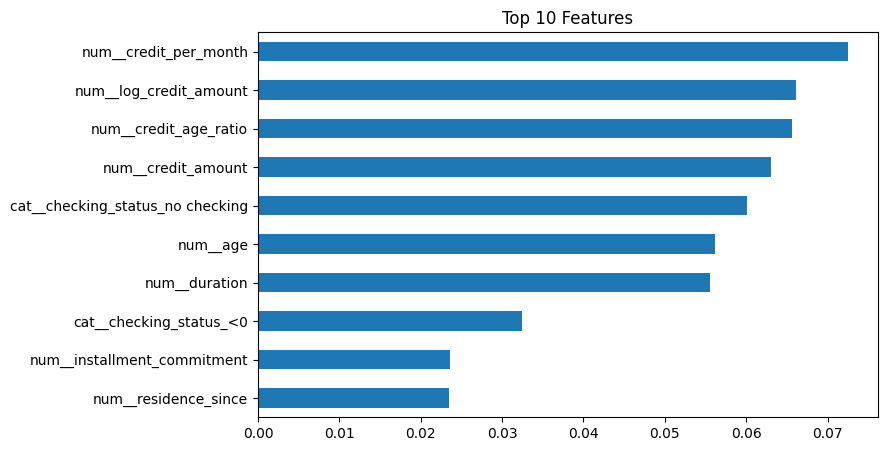

In [22]:
rf = pipes["Random Forest"]
names = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=names)
imp.sort_values().tail(10).plot(kind="barh", figsize=(8, 5), title="Top 10 Features")
plt.show()

## Conclusion

- Three models were compared: Logistic Regression, Decision Tree and Random Forest.
- **Best model: Logistic Regression** with Accuracy 74.5%, Precision 0.55, Recall 0.82, F1-Score 0.66 and ROC-AUC 0.8126.
- Random Forest had a slightly higher accuracy (76.0%) but a low Recall (0.38), so it missed many risky applicants. Decision Tree performed the weakest (ROC-AUC 0.6655).
- Logistic Regression correctly identified 49 of 60 risky applicants in the test set (Recall 0.82).
- In credit scoring, missing a risky borrower costs more than wrongly flagging a good one, so Recall and ROC-AUC matter more than accuracy. Balanced class weights were used because only about 30% of applicants are risky.
- The trade-off is lower Precision (0.55): some good applicants are wrongly flagged as risky.
- Top features: ______ (fill from the feature importance chart)